In [1]:
#easy
!pip install qiskit qiskit-aer

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

# 3 input qubits + 1 output qubit
qc = QuantumCircuit(4, 3)

# Prepare output qubit in |1>
qc.x(3)

# Apply Hadamard gates to all qubits
for i in range(4):
    qc.h(i)

# Constant oracle: f(x) = 0
# No gates are required for this oracle

# Apply Hadamard gates to input qubits
for i in range(3):
    qc.h(i)

# Measure the input qubits
qc.measure([0, 1, 2], [0, 1, 2])

# Simulate
simulator = AerSimulator()
result = simulator.run(qc, shots=1024).result()
counts = result.get_counts()

print("Measurement results:", counts)

if list(counts.keys()) == ['000']:
    print("Result: 000 - Constant function")
else:
    print("Check the measurement results.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 27.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 36.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 62.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.7 MB/s eta 0:00:00
Measurement results: {'000': 1024}
Result: 000 - Constant function


In [2]:
#medium
!pip install qiskit qiskit-aer

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

# 3 input qubits + 1 output qubit
qc = QuantumCircuit(4, 3)

# Prepare output qubit in |-> state
qc.x(3)
qc.h(3)

# Apply Hadamard gates to input qubits
for i in range(3):
    qc.h(i)

# Balanced oracle: parity function f(x) = x0 XOR x1 XOR x2
qc.cx(0, 3)
qc.cx(1, 3)
qc.cx(2, 3)

# Apply final Hadamard gates to input qubits
for i in range(3):
    qc.h(i)

# Measure input qubits
qc.measure([0, 1, 2], [0, 1, 2])

# Simulate
simulator = AerSimulator()
result = simulator.run(qc, shots=1024).result()
counts = result.get_counts()

print("Measurement results:", counts)

if '000' not in counts:
    print("Result: Non-zero bitstring - Balanced function")
else:
    print("Check the measurement results.")


Measurement results: {'111': 1024}
Result: Non-zero bitstring - Balanced function


In [3]:
#hard
!pip install qiskit qiskit-aer

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

def deutsch_jozsa(n, function_type):
    # n input qubits + 1 output qubit
    qc = QuantumCircuit(n + 1, n)

    # Prepare output qubit in |-> state
    qc.x(n)
    qc.h(n)

    # Apply Hadamard to input qubits
    for i in range(n):
        qc.h(i)

    # Construct oracle dynamically
    if function_type == "constant":
        pass  # f(x) = 0

    elif function_type == "balanced":
        # Balanced parity function: f(x) = x0
        qc.cx(0, n)

    else:
        raise ValueError("Choose 'constant' or 'balanced'")

    # Final Hadamard gates
    for i in range(n):
        qc.h(i)

    # Measure input qubits
    for i in range(n):
        qc.measure(i, i)

    return qc

simulator = AerSimulator()

# Test for n = 2 to 5
for n in range(2, 6):
    for function_type in ["constant", "balanced"]:
        qc = deutsch_jozsa(n, function_type)

        result = simulator.run(qc, shots=1024).result()
        counts = result.get_counts()

        print(f"\nn = {n}, Function = {function_type}")
        print("Measurement results:", counts)

        if function_type == "constant" and list(counts.keys()) == ['0' * n]:
            print("Correctly classified as CONSTANT")
        elif function_type == "balanced" and list(counts.keys()) == ['0' * (n-1) + '1']:
            print("Correctly classified as BALANCED")


n = 2, Function = constant
Measurement results: {'00': 1024}
Correctly classified as CONSTANT

n = 2, Function = balanced
Measurement results: {'01': 1024}
Correctly classified as BALANCED

n = 3, Function = constant
Measurement results: {'000': 1024}
Correctly classified as CONSTANT

n = 3, Function = balanced
Measurement results: {'001': 1024}
Correctly classified as BALANCED

n = 4, Function = constant
Measurement results: {'0000': 1024}
Correctly classified as CONSTANT

n = 4, Function = balanced
Measurement results: {'0001': 1024}
Correctly classified as BALANCED

n = 5, Function = constant
Measurement results: {'00000': 1024}
Correctly classified as CONSTANT

n = 5, Function = balanced
Measurement results: {'00001': 1024}
Correctly classified as BALANCED


In [5]:
#challenge
!pip install qiskit qiskit-aer

import random
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

def deutsch_jozsa_random(n):
    # Generate a random balanced Boolean function
    inputs = [format(i, f'0{n}b') for i in range(2**n)]

    outputs = [0] * (2**(n-1)) + [1] * (2**(n-1))
    random.shuffle(outputs)

    function = dict(zip(inputs, outputs))

    # Create circuit
    qc = QuantumCircuit(n + 1, n)

    # Prepare output qubit in |-> state
    qc.x(n)
    qc.h(n)

    # Apply Hadamard gates to input qubits
    for i in range(n):
        qc.h(i)

    # Oracle: |x>|y> -> |x>|y XOR f(x)>
    for x, value in function.items():
        if value == 1:
            bits = [int(b) for b in x[::-1]]

            # Apply X gates to match the selected input
            for i, bit in enumerate(bits):
                if bit == 0:
                    qc.x(i)

            # Multi-controlled X implements the oracle condition
            qc.mcx(list(range(n)), n)

            # Undo X gates
            for i, bit in enumerate(bits):
                if bit == 0:
                    qc.x(i)

    # Final Hadamard gates
    for i in range(n):
        qc.h(i)

    # Measure input qubits
    for i in range(n):
        qc.measure(i, i)

    return qc, function

simulator = AerSimulator()

n = 3
trials = 5

for trial in range(trials):
    qc, function = deutsch_jozsa_random(n)

    result = simulator.run(qc, shots=1024).result()
    counts = result.get_counts()

    print(f"\nTrial {trial + 1}")
    print("Random balanced function:", function)
    print("Measurement results:", counts)

    if '0' * n not in counts:
        print("Correctly classified as BALANCED")
    else:
        print("Classification failed")


Trial 1
Random balanced function: {'000': 0, '001': 0, '010': 1, '011': 1, '100': 0, '101': 0, '110': 1, '111': 1}
Measurement results: {'010': 1024}
Correctly classified as BALANCED

Trial 2
Random balanced function: {'000': 0, '001': 1, '010': 1, '011': 1, '100': 0, '101': 0, '110': 0, '111': 1}
Measurement results: {'010': 266, '100': 247, '111': 259, '001': 252}
Correctly classified as BALANCED

Trial 3
Random balanced function: {'000': 1, '001': 0, '010': 1, '011': 0, '100': 1, '101': 1, '110': 0, '111': 0}
Measurement results: {'101': 235, '001': 252, '010': 269, '110': 268}
Correctly classified as BALANCED

Trial 4
Random balanced function: {'000': 1, '001': 1, '010': 0, '011': 0, '100': 1, '101': 0, '110': 1, '111': 0}
Measurement results: {'001': 242, '010': 248, '110': 270, '101': 264}
Correctly classified as BALANCED

Trial 5
Random balanced function: {'000': 0, '001': 0, '010': 0, '011': 1, '100': 1, '101': 1, '110': 0, '111': 1}
Measurement results: {'001': 247, '110': 23

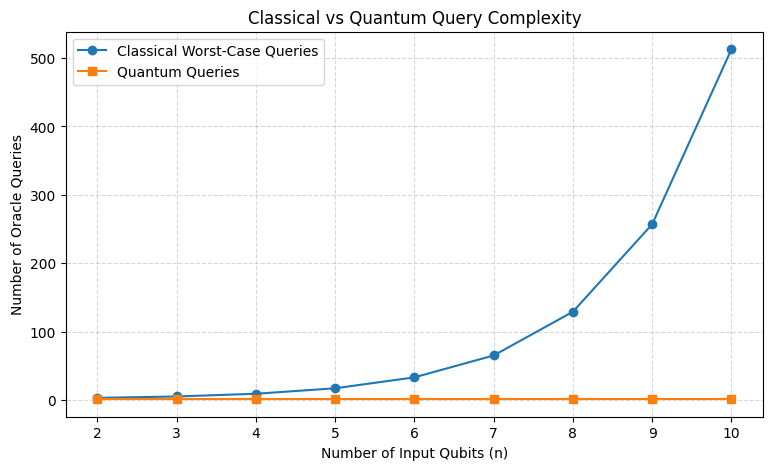

n | Classical Queries | Quantum Queries
----------------------------------------
2 | 3 | 1
3 | 5 | 1
4 | 9 | 1
5 | 17 | 1
6 | 33 | 1
7 | 65 | 1
8 | 129 | 1
9 | 257 | 1
10 | 513 | 1


In [6]:
#real world
import matplotlib.pyplot as plt

# Number of input qubits
n_values = list(range(2, 11))

# Classical worst-case queries for Deutsch-Jozsa
classical_queries = [2**(n - 1) + 1 for n in n_values]

# Quantum queries
quantum_queries = [1 for n in n_values]

# Plot graph
plt.figure(figsize=(9, 5))

plt.plot(n_values, classical_queries, marker='o',
         label='Classical Worst-Case Queries')

plt.plot(n_values, quantum_queries, marker='s',
         label='Quantum Queries')

plt.xlabel('Number of Input Qubits (n)')
plt.ylabel('Number of Oracle Queries')
plt.title('Classical vs Quantum Query Complexity')
plt.xticks(n_values)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

# Display values
print("n | Classical Queries | Quantum Queries")
print("----------------------------------------")

for n, c, q in zip(n_values, classical_queries, quantum_queries):
    print(f"{n} | {c} | {q}")